In [33]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerias importadas correctamente")

Librerias importadas correctamente


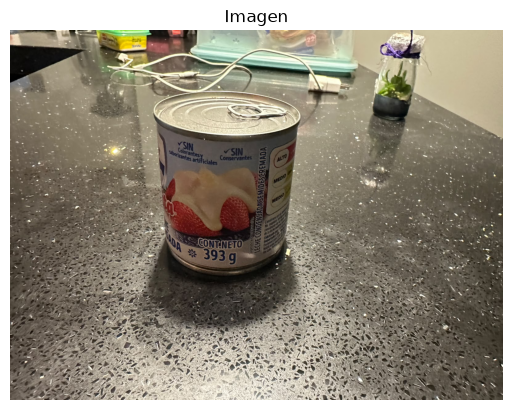

In [34]:
ruta_imagen = "imagenes/lechcon34.jpeg"
imagen = cv2.imread(ruta_imagen)
if imagen is None:
    raise FileNotFoundError("No se encontro la imagen")

imagen_rgb= cv2.cvtColor(imagen,cv2.COLOR_BGR2RGB)
plt.imshow(imagen_rgb)
plt.title("Imagen")
plt.axis("off")
plt.show()


In [35]:
def histograma(eje, gris, titulo, color="#42A5F5"):
    eje.hist(gris.ravel(), bins=256, range=(0, 256), color=color)
    eje.set_title(titulo)
    eje.set_xlim(0, 255)
    eje.set_yticks([])
    
def mostrar(imagenes, titulos, cmap=None, ancho=4):
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(ancho * len(imagenes), ancho))
    for eje, im, t in zip(np.atleast_1d(ejes), imagenes, titulos):
        if im.ndim == 2:
            fijo = im.dtype == np.uint8
            eje.imshow(im, cmap=cmap or "gray", vmin=0 if fijo else None, vmax=255 if fijo else None)
        else:
            eje.imshow(im)
        eje.set_title(t)
        eje.axis("off")
    plt.tight_layout()
    plt.show()


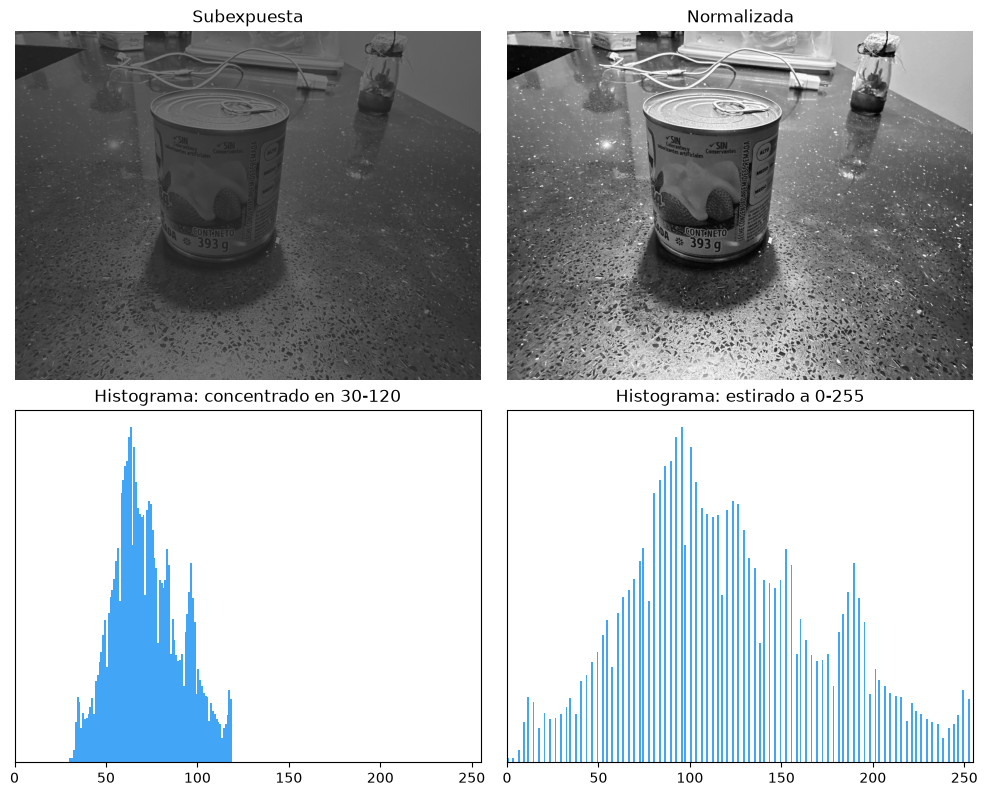

In [36]:
np.random.seed(42)
gris = cv2.cvtColor(imagen_rgb,cv2.COLOR_RGB2GRAY)
subexpuesta = (gris * 0.35 + 30).astype(np.uint8)

minimo, maximo = int(subexpuesta.min()), int(subexpuesta.max())
manual = ((subexpuesta.astype(float) - minimo) / (maximo - minimo) * 255).astype(np.uint8)
opencv = cv2.normalize(subexpuesta, None, 0, 255, cv2.NORM_MINMAX)

fig, ejes = plt.subplots(2, 2, figsize=(10, 8))
ejes[0, 0].imshow(subexpuesta, cmap="gray", vmin=0, vmax=255)
ejes[0, 0].set_title("Subexpuesta")
ejes[0, 1].imshow(opencv, cmap="gray", vmin=0, vmax=255)
ejes[0, 1].set_title("Normalizada")
histograma(ejes[1, 0], subexpuesta, "Histograma: concentrado en 30-120")
histograma(ejes[1, 1], opencv, "Histograma: estirado a 0-255")
for e in ejes[0]:
    e.axis("off")
plt.tight_layout()
plt.show()


Diferencia máxima ecualización manual vs cv2.equalizeHist: 0


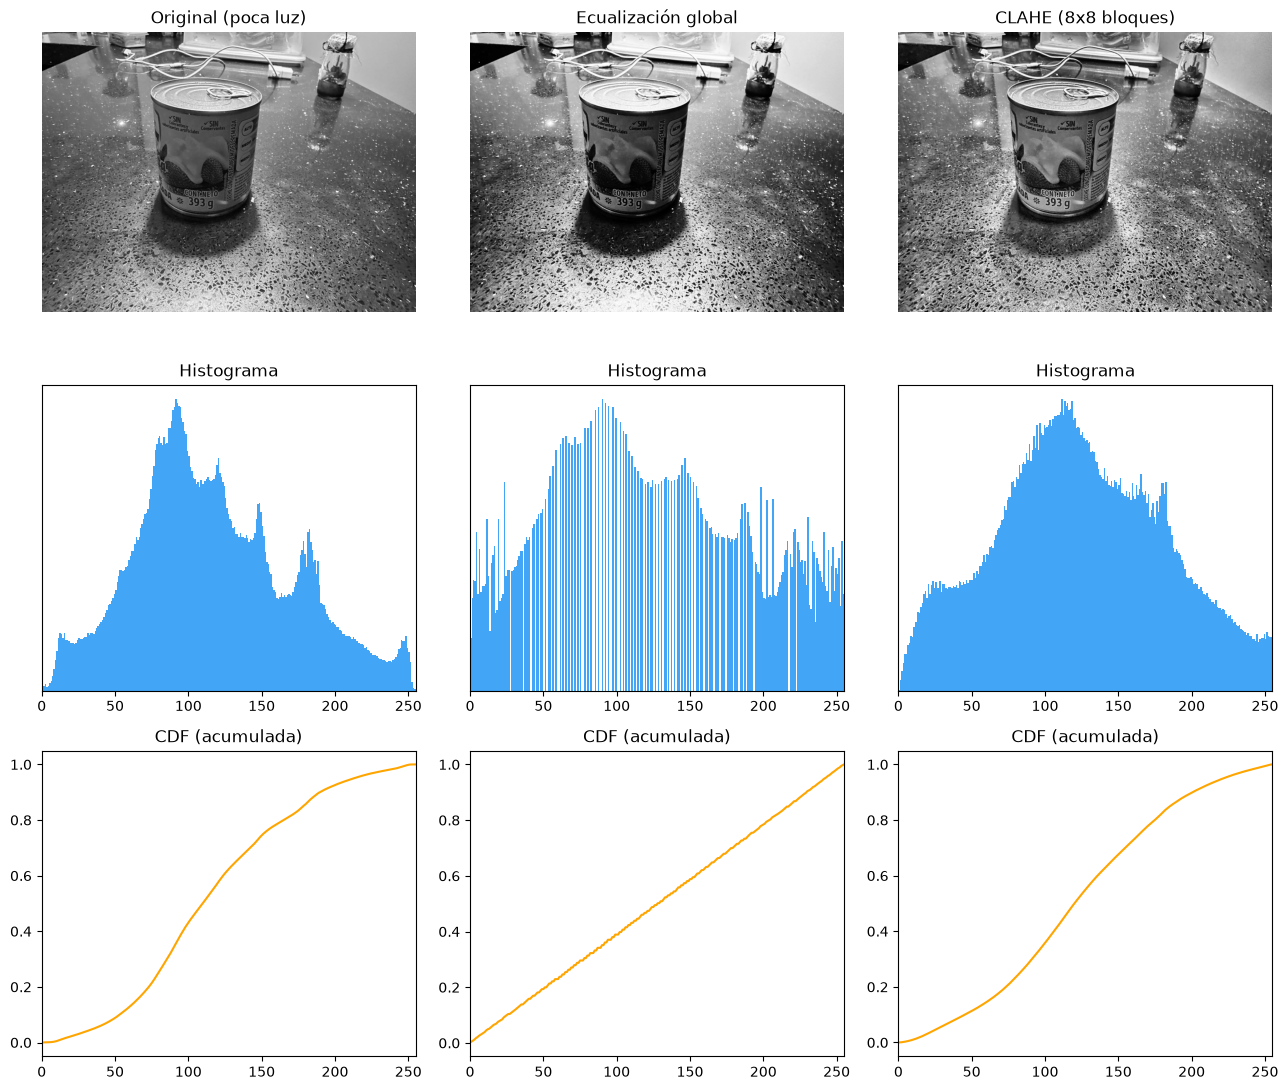

Original    media =  117.0   desviación estándar (contraste) =  52.7
Ecualizada  media =  128.2   desviación estándar (contraste) =  73.5
CLAHE       media =  123.3   desviación estándar (contraste) =  57.1


In [37]:
gris_oscura = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

hist = np.bincount(gris_oscura.ravel(), minlength=256)
cdf = hist.cumsum()
cdf_min = cdf[cdf > 0][0]
tabla = np.round((cdf - cdf_min) / (gris_oscura.size - cdf_min) * 255).clip(0, 255).astype(np.uint8)
ecualizada_manual = tabla[gris_oscura]  # cada nivel v se reemplaza por tabla[v]
ecualizada = cv2.equalizeHist(gris_oscura)
print("Diferencia máxima ecualización manual vs cv2.equalizeHist:",
    np.abs(ecualizada_manual.astype(int) - ecualizada.astype(int)).max())

# CLAHE: ecualización por bloques con límite de contraste (evita amplificar ruido)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gris_oscura)

fig, ejes = plt.subplots(3, 3, figsize=(13, 11))
for c, (img, nombre) in enumerate([(gris_oscura, "Original (poca luz)"),
                                (ecualizada, "Ecualización global"), (clahe, "CLAHE (8x8 bloques)")]):
    ejes[0, c].imshow(img, cmap="gray", vmin=0, vmax=255)
    ejes[0, c].set_title(nombre)
    ejes[0, c].axis("off")
    histograma(ejes[1, c], img, "Histograma")
    cdf_img = np.bincount(img.ravel(), minlength=256).cumsum()
    ejes[2, c].plot(cdf_img / cdf_img[-1], color="orange")
    ejes[2, c].set_title("CDF (acumulada)")
    ejes[2, c].set_xlim(0, 255)
plt.tight_layout()
plt.show()
for nombre, img in [("Original", gris_oscura), ("Ecualizada", ecualizada), ("CLAHE", clahe)]:
    print(f"{nombre:<11} media = {img.mean():6.1f}   desviación estándar (contraste) = {img.std():5.1f}")

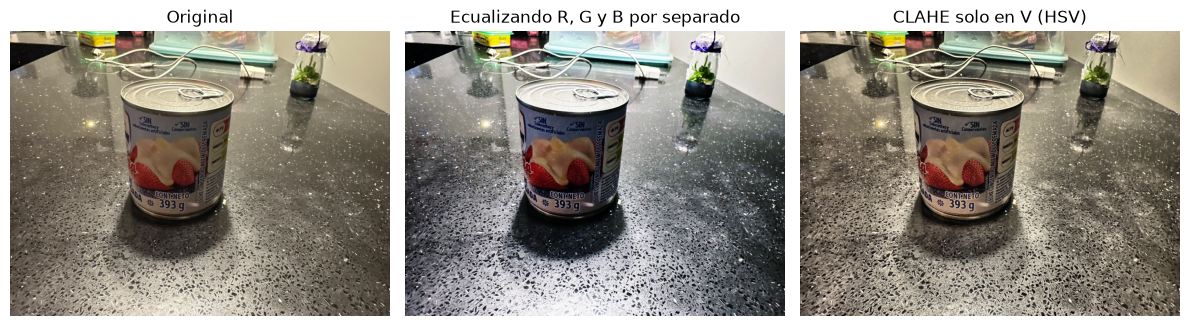

In [38]:
hsv = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2HSV)
hsv_v = hsv.copy()
hsv_v[..., 2] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(hsv[..., 2])
color_v = cv2.cvtColor(hsv_v, cv2.COLOR_HSV2RGB)
por_canal = np.dstack([cv2.equalizeHist(imagen_rgb[..., i]) for i in range(3)])
mostrar([imagen_rgb, por_canal, color_v],
        ["Original", "Ecualizando R, G y B por separado", "CLAHE solo en V (HSV)"])

## 2. Operaciones sobre grupos de puntos: convolución y filtros

**Conceptos clave:**
- **Operación de vecindario:** El nuevo valor de cada píxel depende de su propio valor y del de sus vecinos contiguos.
- **Kernel (filtro o máscara):** Matriz pequeña (por ejemplo 3×3 o 5×5) con coeficientes de ponderación.
- **Convolución:** Desliza el kernel por toda la imagen calculando la suma del producto elemento a elemento en cada vecindad.
- **Filtros lineales vs no lineales:** Los filtros lineales (media, Gaussiano) aplican combinaciones ponderadas; los no lineales (mediana) ordenan los píxeles y seleccionan estadísticos de posición.
- **Ruido:** Gaussiano (variaciones aleatorias continuas por poca luz) y Sal y pimienta (píxeles sueltos negros y blancos).
- **Métrica PSNR (*Peak Signal-to-Noise Ratio*):** Medida en dB de la fidelidad entre la imagen recuperada y la original limpia (mayor valor indica mejor recuperación).


### 2.1 Convolución paso a paso

La convolución calcula una suma ponderada deslizando el kernel $K$ sobre la imagen $I$:

$$(I * K)(x, y) = \sum_i \sum_j I(x+i,\, y+j)\, K(i, j)$$

Programamos la función manual con doble bucle sobre una matriz sintética 6×6 con un salto brusco de intensidad para analizar el comportamiento numérico de suavizado frente a detección de bordes.


In [39]:
# Convolución manual con padding replicado para mantener las dimensiones originales
def convolucion(imagen, kernel):
    k = kernel.shape[0] // 2
    con_borde = np.pad(imagen.astype(float), k, mode="edge")
    salida = np.zeros(imagen.shape, dtype=float)
    for y in range(imagen.shape[0]):
        for x in range(imagen.shape[1]):
            vecindad = con_borde[y:y + 2 * k + 1, x:x + 2 * k + 1]
            salida[y, x] = (vecindad * kernel).sum()
    return salida


# Matriz sintética 6x6 con borde vertical (salto de intensidad de 10 a 200)
pequena = np.array([[10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200]], dtype=np.uint8)

media_3x3 = np.ones((3, 3)) / 9
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)

print("Matriz 6x6 original con salto vertical:\n", pequena)
print("\nConvolución con kernel de Media 3x3 (suaviza):\n", convolucion(pequena, media_3x3).round(0))
print("\nConvolución con Sobel x (detecta borde vertical):\n", convolucion(pequena, sobel_x))


Matriz 6x6 original con salto vertical:
 [[ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]]

Convolución con kernel de Media 3x3 (suaviza):
 [[ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]]

Convolución con Sobel x (detecta borde vertical):
 [[  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]]


> **Observación:** El kernel de **media** transforma el salto brusco 10 → 200 en una rampa suave (10, 73, 137, 200), realizando un **suavizado**. El kernel **Sobel x** da valor 0 en zonas uniformes y genera un valor alto (760) exactamente en el cambio de intensidad, permitiendo **detectar bordes**.


Diferencia máxima entre convolución manual y cv2.filter2D: 0.0


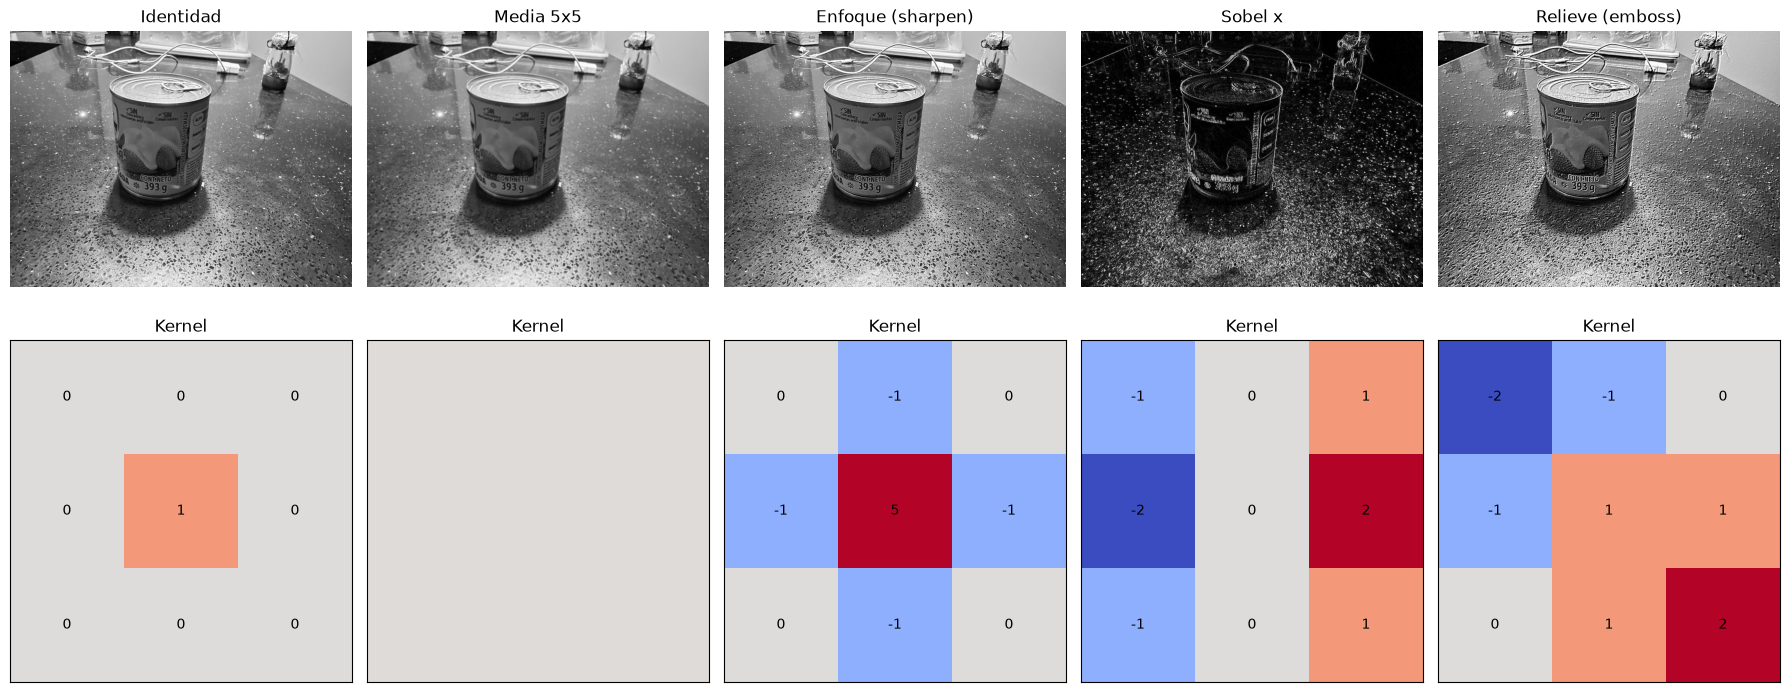

In [40]:
# Validación con cv2.filter2D en un recorte de la fotografía de nuestro producto
recorte = gris[500:600, 700:800]
manual = convolucion(recorte, sobel_x)
opencv = cv2.filter2D(recorte.astype(float), -1, sobel_x, borderType=cv2.BORDER_REPLICATE)
print("Diferencia máxima entre convolución manual y cv2.filter2D:", np.abs(manual - opencv).max())

# Banco de kernels clásicos aplicados a la imagen del producto
kernels = {
    "Identidad": np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], dtype=float),
    "Media 5x5": np.ones((5, 5)) / 25,
    "Enfoque (sharpen)": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
    "Sobel x": sobel_x,
    "Relieve (emboss)": np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=float),
}

fig, ejes = plt.subplots(2, len(kernels), figsize=(18, 7.5))
for c, (nombre, k) in enumerate(kernels.items()):
    salida = cv2.filter2D(gris.astype(float), -1, k)
    if nombre == "Sobel x":
        salida = np.abs(salida)
    ejes[0, c].imshow(np.clip(salida, 0, 255), cmap="gray", vmin=0, vmax=255)
    ejes[0, c].set_title(nombre)
    ejes[0, c].axis("off")
    
    ejes[1, c].imshow(k, cmap="coolwarm", vmin=-2, vmax=2)
    if k.shape[0] == 3:
        for (i, j), v in np.ndenumerate(k):
            ejes[1, c].text(j, i, f"{v:g}", ha="center", va="center")
    ejes[1, c].set_title("Kernel")
    ejes[1, c].set_xticks([])
    ejes[1, c].set_yticks([])

plt.tight_layout()
plt.show()


> **Observación:** La convolución manual y `cv2.filter2D` dan exactamente el mismo resultado (diferencia 0). Con la misma operación matemática y cambiando únicamente los coeficientes del kernel obtenemos efectos muy distintos: copiar la imagen, desenfocarla, enfocar letras y detalles del empaque, detectar bordes verticales o simular relieve.


### 2.2 a 2.5 Filtros de media, mediana y Gaussiano para reducir ruido

| Filtro | Cómo calcula el nuevo píxel | Tipo | Característica |
|---|---|---|---|
| **Media** | Promedio de la vecindad (todos pesan igual) | Lineal | Suavizado simple, desenfoca contornos |
| **Mediana** | Mediana de la vecindad (toma el valor central) | No lineal | Robusto frente a *outliers* (sal y pimienta) |
| **Gaussiano** | Promedio ponderado por distancia: $G(x,y)=\frac{1}{2\pi\sigma^2}e^{-\frac{x^2+y^2}{2\sigma^2}}$ | Lineal | Pondera vecinos cercanos, preservando mejor bordes |

Analizamos primero el kernel Gaussiano variando $\sigma$ y luego realizamos la comparación de los tres filtros inyectando ruido a nuestra fotografía para medir la recuperación con la métrica **PSNR (dB)**.


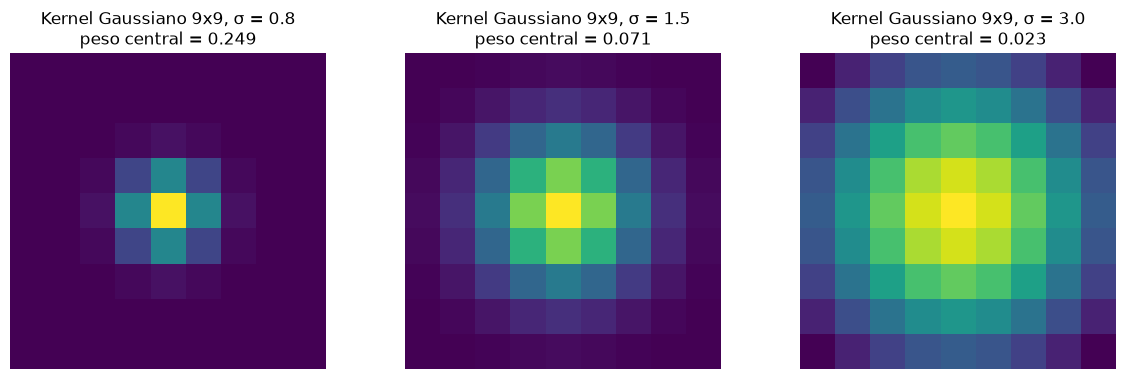

In [41]:
# Visualización del kernel Gaussiano 9x9 con diferentes valores de dispersión sigma
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
for eje, sigma in zip(ejes, [0.8, 1.5, 3.0]):
    g = cv2.getGaussianKernel(9, sigma)
    kernel_2d = g @ g.T
    eje.imshow(kernel_2d, cmap="viridis")
    eje.set_title(f"Kernel Gaussiano 9x9, σ = {sigma}\npeso central = {kernel_2d[4, 4]:.3f}")
    eje.axis("off")

plt.tight_layout()
plt.show()


> **Observación:** Con $\sigma$ pequeño la campana es estrecha y concentra la mayor parte del peso en el centro (suavizado leve); con $\sigma$ grande el peso se dispersa en una vecindad amplia (mayor desenfoque). El parámetro $\sigma$ controla la intensidad del suavizado.


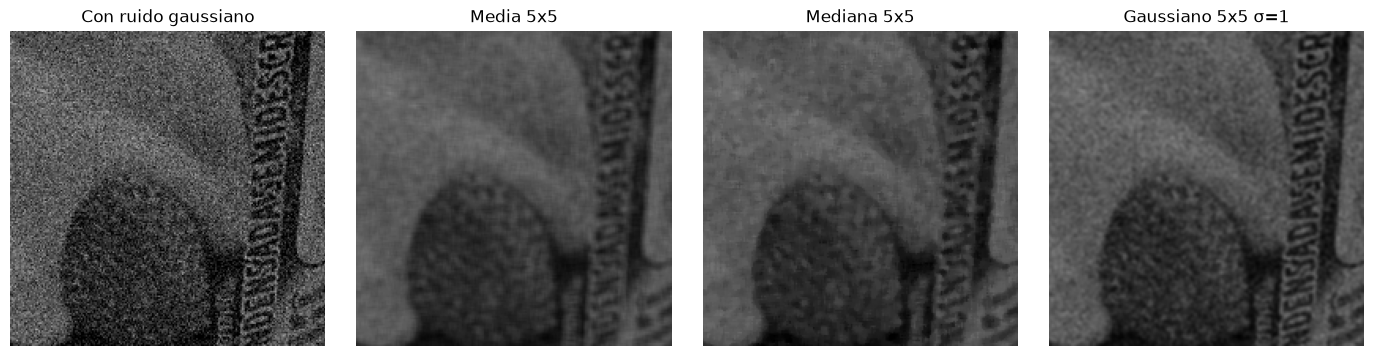

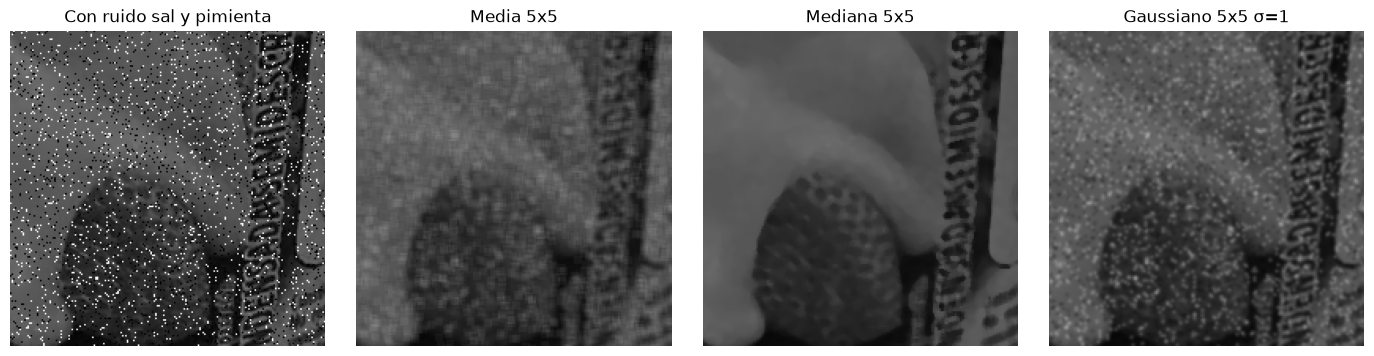

PSNR en dB (más alto = más parecido a la imagen limpia):


,sin filtrar,Media 5x5,Mediana 5x5,Gaussiano 5x5 σ=1
ruido,,,,
Gaussiano (σ=25),20.3,24.0,24.3,26.4
Sal y pimienta (8 %),16.3,23.1,25.2,24.1


In [42]:
limpia = gris.copy()
rng = np.random.default_rng(0)

# Inyección de ruido a la imagen de nuestro producto
ruido_gauss = np.clip(limpia + rng.normal(0, 25, limpia.shape), 0, 255).astype(np.uint8)
ruido_sp = limpia.copy()
mascara = rng.random(limpia.shape)
ruido_sp[mascara < 0.04] = 0      # pimienta: 4 % de píxeles negros
ruido_sp[mascara > 0.96] = 255    # sal: 4 % de píxeles blancos

# Definición de los filtros
filtros = {
    "Media 5x5": lambda im: cv2.blur(im, (5, 5)),
    "Mediana 5x5": lambda im: cv2.medianBlur(im, 5),
    "Gaussiano 5x5 σ=1": lambda im: cv2.GaussianBlur(im, (5, 5), 1.0),
}

# Tabla cuantitativa de métricas PSNR
tabla = []
for nombre_ruido, ruidosa in [("Gaussiano (σ=25)", ruido_gauss), ("Sal y pimienta (8 %)", ruido_sp)]:
    fila = {"ruido": nombre_ruido, "sin filtrar": cv2.PSNR(limpia, ruidosa)}
    for nombre, f in filtros.items():
        fila[nombre] = cv2.PSNR(limpia, f(ruidosa))
    tabla.append(fila)

# Comparación visual con zoom sobre una región con detalles de nuestro producto
zoom = (slice(450, 650), slice(650, 850))
for ruidosa, nombre_ruido in [(ruido_gauss, "ruido gaussiano"), (ruido_sp, "ruido sal y pimienta")]:
    mostrar([ruidosa[zoom]] + [f(ruidosa)[zoom] for f in filtros.values()],
            [f"Con {nombre_ruido}"] + list(filtros), ancho=3.5)

print("PSNR en dB (más alto = más parecido a la imagen limpia):")
pd.DataFrame(tabla).set_index("ruido").round(1)


> **Conclusiones de la comparación:**
> - **Frente a ruido sal y pimienta:** La **mediana** gana con amplia diferencia (25.2 dB vs 23.1 dB de la media). Un píxel extremo aislado (0 o 255) no altera la mediana de la vecindad al ser ordenado, mientras que los filtros de media y Gaussiano lo promedian, dejando manchas difusas.
> - **Frente a ruido gaussiano:** El filtro **Gaussiano** obtiene el mejor resultado (26.4 dB vs 24.0 dB de la media), ya que al otorgar más peso a los vecinos cercanos conserva mejor los contornos y detalles del producto.
> - **Criterio de diseño:** Todo filtro reduce ruido pero elimina detalle fino; por tanto, el filtro debe seleccionarse según el tipo de ruido presente en la escena.
